# 01 — Exploration éCO2mix (France, 2019–2024)

**Projet tutoré GreenGrid AI — Phase 0 (Ramy).** Objectifs :
1. vérifier que les fichiers éCO2mix 2019–2025 contiennent les colonnes dont on a besoin ;
2. caractériser la cible (intensité carbone, gCO₂/kWh) : profils journalier, hebdomadaire, saisonnier, distribution ;
3. mesurer les valeurs manquantes et l'effet des changements d'heure ;
4. en tirer les conséquences pour le cadrage.

> **Règle anti-fuite.** L'année **2025 est le jeu de test verrouillé** (ouverture le 4 janv. 2027).
> Elle n'est lue ici **que pour des contrôles de structure** (présence des colonnes, nombre de lignes, taux de remplissage) —
> aucune statistique ni graphique de la cible n'est calculé sur 2025.
> 2019–2023 = entraînement, 2024 = validation (montrée séparément, pour mesurer le décalage de distribution).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from greengrid.data.eco2mix import (
    read_raw_file, localize_to_utc, load_eco2mix, to_hourly,
    TARGET, TZ_LOCAL, PRODUCTION_COLS,
)

RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = range(2019, 2024), 2024, 2025

# Style : marques fines, grille discrète, texte en encre neutre
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.size": 10.5, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")

## 1. Vérification des fichiers et des colonnes (2019–2025)

Format réel des « .xls » RTE : texte tabulé latin-1, ligne d'avertissement en fin de fichier,
grille de 96 créneaux de 15 min par jour **en heure locale**.

In [2]:
rows, completeness = [], {}
for y in range(2019, 2026):
    raw = read_raw_file(RAW / f"eCO2mix_RTE_Annuel-Definitif_{y}.xls")
    days = raw["ts_local"].dt.date.nunique()
    half = raw[raw["ts_local"].dt.minute.isin([0, 30])]
    quarter = raw[raw["ts_local"].dt.minute.isin([15, 45])]
    rows.append({
        "année": y, "nature": raw["nature"].unique()[0], "jours": days,
        "lignes 15 min": len(raw), "attendu (96/j)": days * 96,
        "Taux CO2 rempli aux :00/:30 (%)": round(half[TARGET].notna().mean() * 100, 1),
        "Taux CO2 rempli aux :15/:45 (%)": round(quarter[TARGET].notna().mean() * 100, 1),
    })
    completeness[y] = (half.drop(columns=["ts_local", "nature"]).notna().mean() * 100).round(0)
files = pd.DataFrame(rows).set_index("année")
files

,nature,jours,lignes 15 min,attendu (96/j),Taux CO2 rempli aux :00/:30 (%),Taux CO2 rempli aux :15/:45 (%)
année,,,,,,
2019,Données définitives,365,35040,35040,100.0,0.0
2020,Données définitives,366,35136,35136,100.0,0.0
2021,Données définitives,365,35040,35040,100.0,0.0
2022,Données définitives,365,35040,35040,100.0,0.0
2023,Données définitives,365,35040,35040,100.0,0.0
2024,Données définitives,366,35136,35136,100.0,0.0
2025,Données définitives,365,35040,35040,100.0,0.0


In [3]:
# Taux de remplissage de chaque colonne (créneaux :00/:30) — structure seulement, y compris 2025
comp = pd.DataFrame(completeness)
comp[comp.min(axis=1) < 100]  # colonnes non complètes sur au moins une année

,2019,2020,2021,2022,2023,2024,2025
battery_charge,0.0,0.0,100.0,100.0,100.0,100.0,100.0
battery_discharge,0.0,0.0,100.0,100.0,100.0,100.0,100.0
wind_onshore,0.0,0.0,100.0,100.0,100.0,100.0,100.0
wind_offshore,0.0,0.0,100.0,100.0,100.0,100.0,100.0


**Constats colonnes**
- Les 7 fichiers sont en **« Données définitives »** et complets (365/366 jours × 96 créneaux).
- **Toutes les colonnes utiles** (consommation, prévisions RTE J-1/J, 8 filières + sous-filières, échanges physiques et commerciaux, *Taux de CO2*) sont remplies à 100 % aux créneaux :00/:30.
- Les créneaux :15/:45 sont vides pour la cible → **résolution réelle = 30 min**.
- Seules `battery_*`, `wind_onshore`, `wind_offshore` n'existent qu'à partir de 2021 (« ND » avant) — non bloquant, l'agrégat `wind` existe depuis 2019.

## 2. Changements d'heure

In [4]:
raw19 = read_raw_file(RAW / "eCO2mix_RTE_Annuel-Definitif_2019.xls")
h19 = raw19[raw19["ts_local"].dt.minute.isin([0, 30])].set_index("ts_local")
cols = ["consumption", "nuclear", TARGET]
print("Mars 2019 — l'heure 02:00–02:59 n'existe pas, mais figure dans le fichier :")
display(h19.loc["2019-03-31 01:00":"2019-03-31 03:30", cols])

Mars 2019 — l'heure 02:00–02:59 n'existe pas, mais figure dans le fichier :


,consumption,nuclear,co2_intensity
ts_local,,,
2019-03-31 01:00:00,48139.0,47652.0,26.0
2019-03-31 01:30:00,47805.0,47703.0,25.0
2019-03-31 02:00:00,47262.0,47493.0,27.0
2019-03-31 02:30:00,47805.0,47703.0,25.0
2019-03-31 03:00:00,47262.0,47493.0,27.0
2019-03-31 03:30:00,47329.0,47219.0,27.0


Les lignes 02:00 et 02:30 du 31 mars sont des **recopies** (02:30 = 01:30, 02:00 = 03:00) : elles sont supprimées au passage en UTC.
En octobre, l'heure 02:00–02:59 est vécue deux fois mais n'apparaît qu'une fois : **une heure réelle manque**.
Convention retenue : l'heure ambiguë est interprétée comme la 1re occurrence (heure d'été) ; le trou est laissé en NaN et sera imputé en phase 1.

In [5]:
dst = []
for y in range(2019, 2026):
    raw = read_raw_file(RAW / f"eCO2mix_RTE_Annuel-Definitif_{y}.xls")
    half = raw[raw["ts_local"].dt.minute.isin([0, 30])]
    utc, stats = localize_to_utc(half)
    grid = pd.date_range(pd.Timestamp(f"{y}-01-01", tz=TZ_LOCAL), pd.Timestamp(f"{y+1}-01-01", tz=TZ_LOCAL),
                         freq="30min", inclusive="left").tz_convert("UTC")
    miss = grid.difference(utc.index)
    dst.append({"année": y, "recopies supprimées (mars)": stats["nonexistent_dropped"],
                "créneaux ambigus (oct.)": stats["ambiguous_as_cest"],
                "demi-heures manquantes (UTC)": len(miss),
                "trou": f"{miss.min():%Y-%m-%d %H:%M} UTC" if len(miss) else "—"})
pd.DataFrame(dst).set_index("année")

,recopies supprimées (mars),créneaux ambigus (oct.),demi-heures manquantes (UTC),trou
année,,,,
2019,2,2,2,2019-10-27 01:00 UTC
2020,2,2,2,2020-10-25 01:00 UTC
2021,2,2,2,2021-10-31 01:00 UTC
2022,2,2,2,2022-10-30 01:00 UTC
2023,2,2,2,2023-10-29 01:00 UTC
2024,2,2,2,2024-10-27 01:00 UTC
2025,2,2,2,2025-10-26 01:00 UTC


## 3. Passage au pas horaire et valeurs manquantes (2019–2024)

À partir d'ici, **seules 2019–2024 sont chargées**.

In [6]:
df30 = load_eco2mix(RAW, range(2019, 2025))
loc30 = df30.index.tz_convert(TZ_LOCAL)
df30 = df30[(loc30.year >= 2019) & (loc30.year <= 2024)]
h = to_hourly(df30)
h = h[(h.index.tz_convert(TZ_LOCAL).year >= 2019)]
lt = h.index.tz_convert(TZ_LOCAL)
h["year"], h["month"], h["dow"], h["hour"] = lt.year, lt.month, lt.dayofweek, lt.hour
h["split"] = np.where(h["year"] <= 2023, "train", "validation")
print(f"{len(h):,} heures UTC de {h.index.min()} à {h.index.max()}")
print("Heures sans aucune observation :", int((h['n_obs'] == 0).sum()), "(= 1 par changement d'heure d'octobre)")
print("Heures avec 1 seule demi-heure :", int((h['n_obs'] == 1).sum()))

52,608 heures UTC de 2018-12-31 23:00:00+00:00 à 2024-12-31 22:00:00+00:00
Heures sans aucune observation : 6 (= 1 par changement d'heure d'octobre)
Heures avec 1 seule demi-heure : 0


## 4. Que mesure exactement « Taux de CO2 » ?

On reconstruit l'intensité à partir du mix **de production française** avec des facteurs d'émission usuels
(charbon 986, fioul 777, gaz 429, bioénergies 494 gCO₂/kWh ; nucléaire, hydraulique, éolien, solaire = 0).

In [7]:
prod = df30[PRODUCTION_COLS].clip(lower=0).sum(axis=1)
recon = (df30["coal"] * 986 + df30["oil"] * 777 + df30["gas"] * 429 + df30["bioenergy"] * 494) / prod
r = np.corrcoef(recon, df30[TARGET])[0, 1]
print(f"corrélation reconstruction / Taux de CO2 RTE : r = {r:.3f}")
print(f"écart absolu médian : {(recon - df30[TARGET]).abs().median():.1f} gCO2/kWh")
print("valeurs distinctes de la cible :", np.sort(df30[TARGET].unique())[:12], "…  (entiers)")

corrélation reconstruction / Taux de CO2 RTE : r = 0.993
écart absolu médian : 8.8 gCO2/kWh
valeurs distinctes de la cible : [ 7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.] …  (entiers)


**Conséquences.** La corrélation très forte confirme que la cible est une **intensité moyenne de la production française** (l'écart médian vient des facteurs exacts de RTE, différents des nôtres) :
les imports ne sont pas comptés (ce n'est ni une intensité « consommation », ni une intensité **marginale**).
Elle est publiée en **entiers** : un pas de 1 g représente ~7 % de la médiane 2024 (15 g) — les écarts de quelques grammes entre modèles seront à interpréter avec prudence.

## 5. Graphes clés (entraînement 2019–2023)

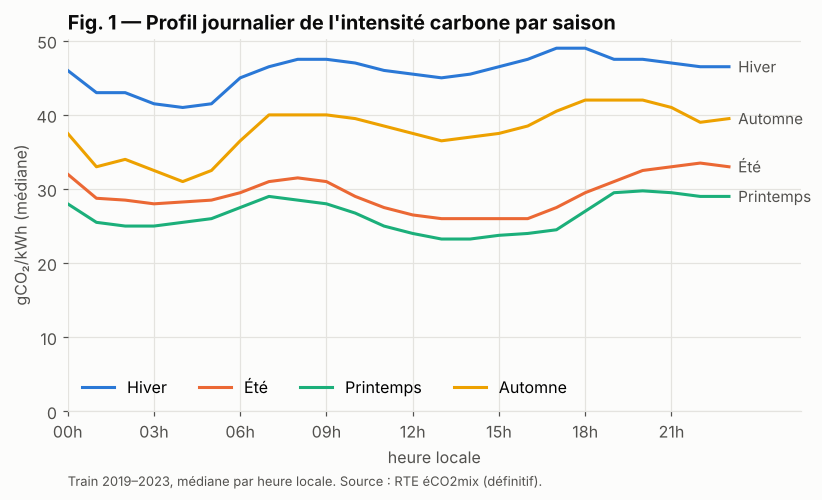

season
Automne      11.0
Hiver         8.0
Printemps     6.0
Été           8.0
Name: amplitude intra-journalière (g), dtype: float64


In [8]:
train = h[h["split"] == "train"]
SEASONS = {12: "Hiver", 1: "Hiver", 2: "Hiver", 3: "Printemps", 4: "Printemps", 5: "Printemps",
           6: "Été", 7: "Été", 8: "Été", 9: "Automne", 10: "Automne", 11: "Automne"}
train = train.assign(season=train["month"].map(SEASONS))
prof = train.groupby(["season", "hour"])[TARGET].median().unstack(0)

fig, ax = plt.subplots(figsize=(8.6, 4.4))
order = [("Hiver", BLUE), ("Été", ORANGE), ("Printemps", AQUA), ("Automne", YELLOW)]
for s, c in order:
    ax.plot(prof.index, prof[s], color=c, label=s)
    ax.annotate(s, (23, prof[s].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=10)
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels([f"{x:02d}h" for x in range(0, 24, 3)])
ax.set_xlim(0, 25.5); ax.set_ylim(0, None)
ax.set_ylabel("gCO₂/kWh (médiane)"); ax.set_xlabel("heure locale")
ax.set_title("Fig. 1 — Profil journalier de l'intensité carbone par saison")
ax.legend(loc="lower left", ncol=4)
ax.text(0, -0.2, "Train 2019–2023, médiane par heure locale. Source : RTE éCO2mix (définitif).",
        transform=ax.transAxes, color=INK2, fontsize=8.5)
save(fig, "fig1_profil_journalier_saison.png"); plt.show()
print((prof.max() - prof.min()).round(0).rename("amplitude intra-journalière (g)"))

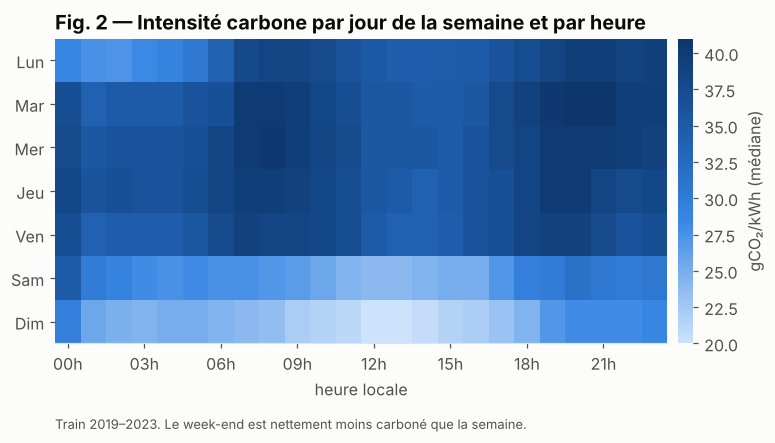

,Lun,Mar,Mer,Jeu,Ven,Sam,Dim
médiane (g),34.5,38.0,38.0,37.5,36.5,28.0,24.0


In [9]:
DAYS = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
heat = train.groupby(["dow", "hour"])[TARGET].median().unstack()
fig, ax = plt.subplots(figsize=(8.6, 3.6))
cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
im = ax.imshow(heat.values, aspect="auto", cmap=cmap)
ax.grid(False)
ax.set_yticks(range(7)); ax.set_yticklabels(DAYS)
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels([f"{x:02d}h" for x in range(0, 24, 3)])
ax.set_xlabel("heure locale")
cb = fig.colorbar(im, ax=ax, pad=0.015); cb.outline.set_visible(False); cb.set_label("gCO₂/kWh (médiane)", color=INK2)
ax.set_title("Fig. 2 — Intensité carbone par jour de la semaine et par heure")
ax.text(0, -0.28, "Train 2019–2023. Le week-end est nettement moins carboné que la semaine.",
        transform=ax.transAxes, color=INK2, fontsize=8.5)
save(fig, "fig2_heatmap_semaine_heure.png"); plt.show()
train.groupby("dow")[TARGET].median().set_axis(DAYS).rename("médiane (g)").to_frame().T

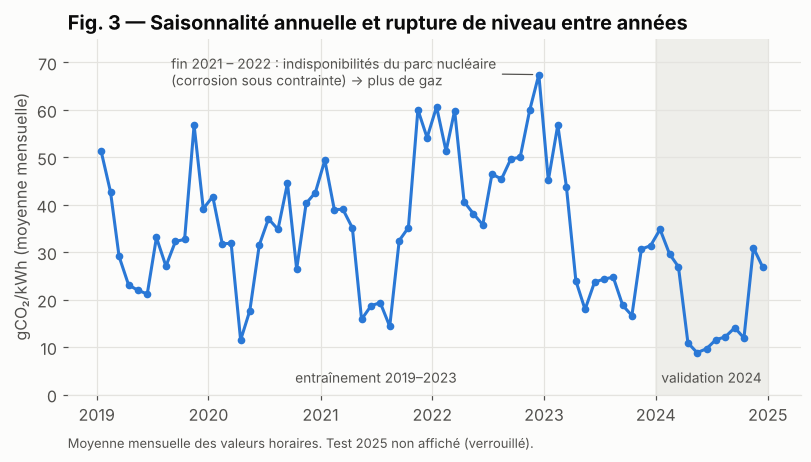

,mean,50%,std,min,max
year,,,,,
2019,34.2,32.0,16.6,8.0,102.0
2020,32.7,33.0,14.1,7.0,81.0
2021,34.3,31.0,18.7,7.0,91.5
2022,50.5,49.0,17.5,12.0,107.0
2023,29.7,26.0,16.6,7.0,93.0
2024,19.0,15.0,12.1,7.0,68.0


In [10]:
monthly = h[TARGET].groupby([h["year"], h["month"]]).mean()
monthly.index = pd.to_datetime([f"{y}-{m:02d}-15" for y, m in monthly.index])
fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="#eeeeea", zorder=0)
ax.plot(monthly.index, monthly.values, color=BLUE, marker="o", markersize=4)
ax.set_ylim(0, None); ax.set_ylabel("gCO₂/kWh (moyenne mensuelle)")
ann = dict(color=INK2, fontsize=9)
ax.set_ylim(0, 75)
peak = monthly.idxmax()
ax.annotate("fin 2021 – 2022 : indisponibilités du parc nucléaire\n(corrosion sous contrainte) → plus de gaz",
            (peak, monthly.max()), xytext=(pd.Timestamp("2019-09-01"), 68), textcoords="data",
            va="center", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8, shrinkB=4), **ann)
ax.text(pd.Timestamp("2024-07-01"), 2.5, "validation 2024", ha="center", **ann)
ax.text(pd.Timestamp("2021-07-01"), 2.5, "entraînement 2019–2023", ha="center", **ann)
ax.set_title("Fig. 3 — Saisonnalité annuelle et rupture de niveau entre années")
ax.text(0, -0.15, "Moyenne mensuelle des valeurs horaires. Test 2025 non affiché (verrouillé).",
        transform=ax.transAxes, color=INK2, fontsize=8.5)
save(fig, "fig3_mensuel_2019_2024.png"); plt.show()
h.groupby("year")[TARGET].describe()[["mean", "50%", "std", "min", "max"]].round(1)

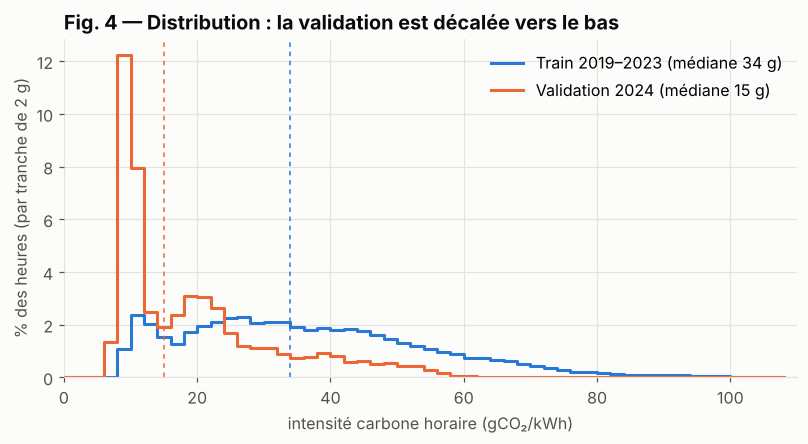

In [11]:
fig, ax = plt.subplots(figsize=(8.6, 4.0))
bins = np.arange(0, 111, 2)
for name, c, lab in [("train", BLUE, "Train 2019–2023"), ("validation", ORANGE, "Validation 2024")]:
    v = h.loc[h["split"] == name, TARGET]
    dens, edges = np.histogram(v, bins=bins, density=True)
    ax.step(edges[:-1], dens * 100, where="post", color=c, label=f"{lab} (médiane {v.median():.0f} g)")
    ax.axvline(v.median(), color=c, lw=1, ls=(0, (3, 3)))
ax.set_xlim(0, 110); ax.set_ylim(0, None)
ax.set_xlabel("intensité carbone horaire (gCO₂/kWh)"); ax.set_ylabel("% des heures (par tranche de 2 g)")
ax.legend(loc="upper right")
ax.set_title("Fig. 4 — Distribution : la validation est décalée vers le bas")
save(fig, "fig4_distribution_train_val.png"); plt.show()

## 6. Ordre de grandeur des baselines naïves (pour fixer la barre)

In [12]:
s = h[TARGET]
base = pd.DataFrame({
    "Persistance J-1 (MAE)": (s - s.shift(24)).abs().groupby(h["year"]).mean(),
    "Saisonnière J-7 (MAE)": (s - s.shift(168)).abs().groupby(h["year"]).mean(),
    "Moyenne annuelle": s.groupby(h["year"]).mean(),
}).round(1)
base["MAE J-1 / moyenne"] = (base["Persistance J-1 (MAE)"] / base["Moyenne annuelle"]).map("{:.0%}".format)
base

,Persistance J-1 (MAE),Saisonnière J-7 (MAE),Moyenne annuelle,MAE J-1 / moyenne
year,,,,
2019,7.6,10.5,34.2,22%
2020,6.4,8.7,32.7,20%
2021,7.3,11.7,34.3,21%
2022,7.9,12.3,50.5,16%
2023,6.5,10.0,29.7,22%
2024,4.3,6.5,19.0,23%


*Indicatif, calculé sur toutes les heures (pas encore le protocole à origine glissante de la phase 2).*
J-1 bat nettement J-7 chaque année : c'est bien **J-1 la barre à battre**.

## 7. Ce qu'on retient pour le cadrage

| Constat | Conséquence |
|---|---|
| Colonnes complètes 2019–2025, définitives, pas 30 min | Données exploitables ; ré-échantillonnage horaire sans perte |
| 2 recopies en mars, 1 h manquante en octobre / an | Passage en UTC obligatoire ; 6 h à imputer sur 2019–2024 |
| Cible = intensité moyenne de la **production** FR (r = 0,993 avec une reconstruction par le mix), publiée en entiers | À dire explicitement ; ce n'est pas une intensité marginale ni « consommation » (imports exclus) |
| Amplitude du profil journalier médian faible (6–11 g) ; effet week-end (−10 à −14 g) et saison (×2 hiver/printemps) forts | La recommandation doit pouvoir décaler au-delà de la journée (horizon 48 h utile) |
| Niveau 2024 ≈ moitié de 2019–2023 (rupture 2022 → reprise nucléaire) | **Risque de biais** : un modèle appris sur 2019–2023 surestimera 2024–2025 → ré-entraînement glissant, features en écarts aux lags, suivi du biais (erreur moyenne) en plus de MAE/RMSE |
| MAE J-1 ≈ 4–8 g selon l'année | Barre à battre ; comparer les modèles **par année**, pas seulement en global |